# UCS420 – Assignment 10
## Heart Health Information Assistant

**Student:** Mehakdeep Kaur  
**Roll Number:** 1024170364 (Even)  
**Course:** UCS420 – Cognitive Computing  
**

## 1. Import libraries and prepare the environment



In [1]:
import sys, subprocess, importlib.util, os, json, re, warnings
warnings.filterwarnings("ignore")

required = ["pandas", "numpy", "sklearn", "nltk", "matplotlib", "seaborn", "ipywidgets", "joblib"]
packages = {"sklearn": "scikit-learn", "ipywidgets": "ipywidgets"}
for module in required:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", packages.get(module, module)])

import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.base import clone
import joblib
from IPython.display import display, Markdown, clear_output
import ipywidgets as widgets

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Environment ready.")

Environment ready.


In [3]:
# Upload all required supporting files together in Google Colab.
required_files = ["dataset.csv", "taxonomy.json", "ontology.json", "knowledge_base.json"]

missing_files = [name for name in required_files if not os.path.exists(name)]

if missing_files:
    try:
        from google.colab import files
        print("Please select these four files from the extracted project folder:")
        print(", ".join(missing_files))
        uploaded = files.upload()  # Select all four files in the same file-picker window.
    except ImportError:
        print("Not running in Google Colab. Place the four files in the same folder as this notebook.")

still_missing = [name for name in required_files if not os.path.exists(name)]
if still_missing:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(still_missing) +
        ". Run this cell again and upload all four supporting files."
    )

print("All supporting files are available:")
for name in required_files:
    print("✓", name)


Please select these four files from the extracted project folder:
dataset.csv, taxonomy.json, ontology.json, knowledge_base.json


Saving dataset.csv to dataset.csv
Saving knowledge_base.json to knowledge_base.json
Saving ontology.json to ontology.json
Saving taxonomy.json to taxonomy.json
All supporting files are available:
✓ dataset.csv
✓ taxonomy.json
✓ ontology.json
✓ knowledge_base.json


## 2. Labelled corpus



In [4]:
# The CSV is included in the GitHub repository.
# If it is not present in the current notebook directory, upload dataset.csv to Colab.
DATASET_PATH = "dataset.csv"
if not os.path.exists(DATASET_PATH):
    try:
        from google.colab import files
        print("Upload dataset.csv from the project folder.")
        uploaded = files.upload()
    except Exception:
        pass

if os.path.exists(DATASET_PATH):
    corpus_df = pd.read_csv(DATASET_PATH)
else:
    raise FileNotFoundError("dataset.csv is required. Upload it or clone the GitHub repository first.")

assert {"query", "intent"}.issubset(corpus_df.columns)
assert len(corpus_df) >= 40
assert corpus_df["intent"].nunique() >= 5
print("Number of queries:", len(corpus_df))
print("Number of intent categories:", corpus_df["intent"].nunique())
display(corpus_df.groupby("intent").size().rename("query_count").to_frame())
display(corpus_df.head())

Number of queries: 80
Number of intent categories: 8


,query_count
intent,
blood_pressure,10
chest_pain,10
cholesterol,10
healthy_diet,10
heart_tests,10
medication_safety,10
physical_activity,10
prevention_risk,10


,query,intent
0,what can cause chest discomfort,chest_pain
1,why does my chest hurt sometimes,chest_pain
2,explain common reasons for chest pain,chest_pain
3,what should I know about tightness in the chest,chest_pain
4,can heartburn feel like chest pain,chest_pain


## 3. Hierarchical taxonomy



In [5]:
with open("taxonomy.json", "r", encoding="utf-8") as f:
    taxonomy = json.load(f)

for major, subcategories in taxonomy.items():
    print(major)
    for subcategory, intents in subcategories.items():
        print("  ├─", subcategory, "→", ", ".join(intents))

Cardiovascular Symptoms
  ├─ Chest-related concerns → chest_pain
  ├─ General warning signs → prevention_risk
Cardiovascular Measurements
  ├─ Blood pressure → blood_pressure
  ├─ Blood lipids → cholesterol
Heart-healthy Living
  ├─ Nutrition → healthy_diet
  ├─ Physical activity and prevention → physical_activity, prevention_risk
Clinical Care and Monitoring
  ├─ Medicines and safety → medication_safety
  ├─ Diagnostic tests → heart_tests


## 4. Ontology: domain concepts and relationships



In [6]:
with open("ontology.json", "r", encoding="utf-8") as f:
    ontology = json.load(f)

print("Concepts:", len(ontology["concepts"]))
for concept in ontology["concepts"]:
    print("-", concept)
print("\nRelationships:", len(ontology["relationships"]))
for subject, relation, object_ in ontology["relationships"]:
    print(f"{subject} --{relation}--> {object_}")

Concepts: 14
- Heart
- Blood
- BloodPressure
- Cholesterol
- LDL
- HDL
- PhysicalActivity
- HealthyDiet
- Smoking
- Diabetes
- Medication
- ECG
- Echocardiogram
- Clinician

Relationships: 14
Blood --circulates_through--> Heart
BloodPressure --measures_force_of--> Blood
LDL --is_a_type_of--> Cholesterol
HDL --is_a_type_of--> Cholesterol
HealthyDiet --can_support_management_of--> Cholesterol
PhysicalActivity --supports--> HeartHealth
Smoking --increases_risk_of--> CardiovascularDisease
Diabetes --is_a_risk_factor_for--> CardiovascularDisease
Medication --is_prescribed_or_reviewed_by--> Clinician
ECG --records_electrical_activity_of--> Heart
Echocardiogram --uses_ultrasound_to_image--> Heart
Clinician --interprets--> HeartTests
HealthyDiet --supports--> HeartHealth
PhysicalActivity --may_help_manage--> BloodPressure


## 5. NLP preprocessing

The preprocessing pipeline performs:
1. Lowercase conversion
2. Tokenization
3. Stopword removal
4. Lemmatization

We retain clinically meaningful negation words such as `no`, `not`, and `never` instead of removing them as stopwords.

In [7]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english")) - {"no", "not", "never", "without"}

def preprocess_text(text):
    text = str(text).lower()
    tokens = re.findall(r"[a-z]+", text)  # tokenization
    tokens = [token for token in tokens if token not in stop_words]  # stopword removal
    tokens = [lemmatizer.lemmatize(token) for token in tokens]  # lemmatization
    return " ".join(tokens)

sample = "What are the causes of chest pains?"
print("Original:", sample)
print("Processed:", preprocess_text(sample))

corpus_df["processed_query"] = corpus_df["query"].apply(preprocess_text)
display(corpus_df[["query", "processed_query", "intent"]].head(10))

Original: What are the causes of chest pains?
Processed: cause chest pain


,query,processed_query,intent
0,what can cause chest discomfort,cause chest discomfort,chest_pain
1,why does my chest hurt sometimes,chest hurt sometimes,chest_pain
2,explain common reasons for chest pain,explain common reason chest pain,chest_pain
3,what should I know about tightness in the chest,know tightness chest,chest_pain
4,can heartburn feel like chest pain,heartburn feel like chest pain,chest_pain
5,what does pressure in my chest mean,pressure chest mean,chest_pain
6,tell me about non emergency causes of chest di...,tell non emergency cause chest discomfort,chest_pain
7,how is chest pain usually assessed by a doctor,chest pain usually assessed doctor,chest_pain
8,what information should I note when chest disc...,information note chest discomfort occurs,chest_pain
9,can muscle strain cause pain around the chest,muscle strain cause pain around chest,chest_pain


## 6. TF-IDF feature extraction and Logistic Regression


In [8]:
X = corpus_df["query"]
y = corpus_df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        preprocessor=preprocess_text,
        tokenizer=str.split,
        token_pattern=None,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
])

model.fit(X_train, y_train)
print("Model training completed.")
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Model training completed.
Training examples: 60
Testing examples: 20


## 7. Model evaluation


,Metric,Score
0,Accuracy,0.750
1,Precision (weighted),0.825
2,Recall (weighted),0.750
3,F1-score (weighted),0.747


                   precision    recall  f1-score   support

   blood_pressure       0.50      1.00      0.67         2
       chest_pain       1.00      1.00      1.00         2
      cholesterol       1.00      0.33      0.50         3
     healthy_diet       1.00      0.67      0.80         3
      heart_tests       0.67      0.67      0.67         3
medication_safety       1.00      1.00      1.00         2
physical_activity       0.50      0.67      0.57         3
  prevention_risk       1.00      1.00      1.00         2

         accuracy                           0.75        20
        macro avg       0.83      0.79      0.78        20
     weighted avg       0.82      0.75      0.75        20



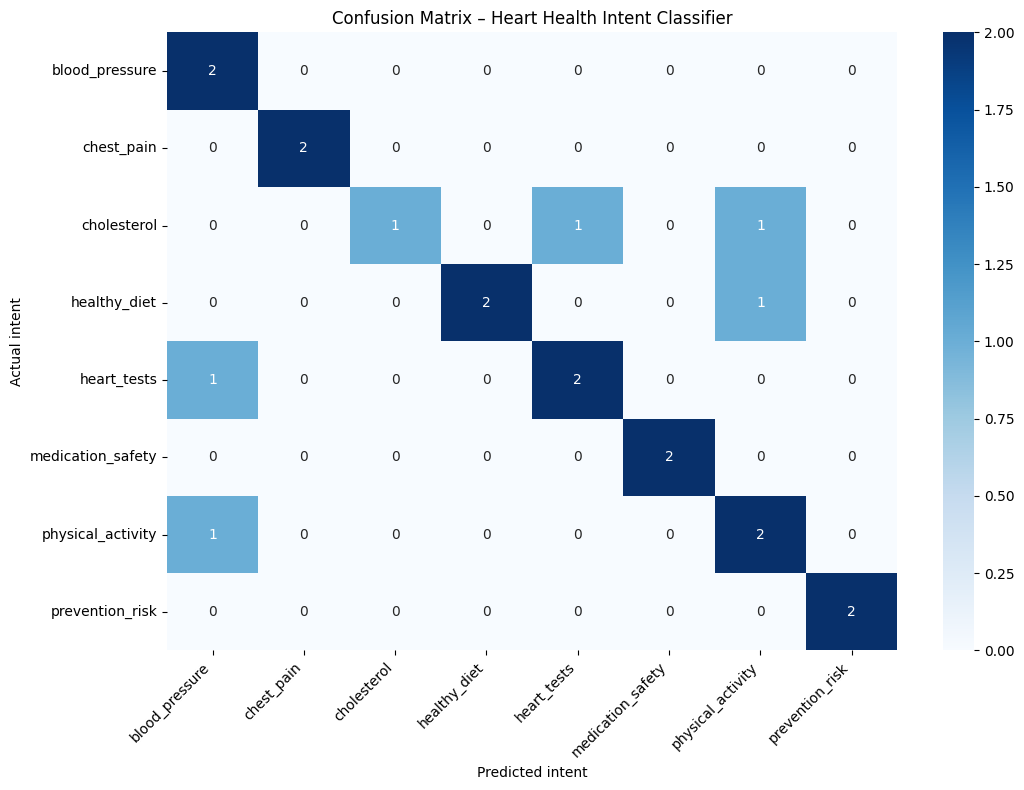

In [9]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"],
    "Score": [accuracy, precision, recall, f1]
})
display(metrics_df.style.format({"Score": "{:.3f}"}))
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(11, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Confusion Matrix – Heart Health Intent Classifier")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Domain-specific knowledge base



In [10]:
with open("knowledge_base.json", "r", encoding="utf-8") as f:
    knowledge_base = json.load(f)

print("Knowledge base intent entries:", len(knowledge_base))
for intent, item in knowledge_base.items():
    print("\n", intent, ":", item["title"])
    print(item["response"])

Knowledge base intent entries: 8

 chest_pain : Chest discomfort: general information
Chest discomfort can have many causes, including heart, lung, digestive, muscle or anxiety-related conditions. It is not possible to identify the cause from a chat. New, unexplained, persistent or recurring chest discomfort should be assessed by a healthcare professional. If it is severe, sudden, or accompanied by breathlessness, sweating, faintness, nausea, or pain spreading to the arm, back, neck or jaw, seek emergency help immediately.

 blood_pressure : Blood pressure
Blood pressure is the force of blood against artery walls. A reading has two numbers: systolic pressure (when the heart contracts) and diastolic pressure (when the heart relaxes). Readings vary, so use a properly fitting cuff, rest quietly before measuring, and follow your clinician's advice. A single reading does not establish a diagnosis.

 cholesterol : Cholesterol and lipid profile
Cholesterol is a fatty substance carried in the 

## 9. Rule-based reasoning



In [11]:
EMERGENCY_PHRASES = [
    "severe chest pain", "crushing chest pain", "chest pain and shortness of breath",
    "chest pain with breathlessness", "cannot breathe", "can't breathe",
    "difficulty breathing", "fainting", "passed out", "unconscious",
    "sudden weakness", "face drooping", "sudden trouble speaking",
    "chest pressure with sweating", "pain spreading to my arm",
    "pain spreading to my jaw"
]

DOMAIN_TERMS = {
    "heart", "cardiac", "chest", "blood", "pressure", "cholesterol", "ldl", "hdl",
    "pulse", "ecg", "ekg", "echocardiogram", "heartburn", "exercise", "walking",
    "diet", "salt", "fat", "smoking", "tobacco", "diabetes", "medicine", "medication",
    "lipid", "artery", "arteries", "cardiovascular", "symptom", "health", "doctor",
    "clinician", "test", "stress", "triglyceride", "systolic", "diastolic"
}

LOW_CONFIDENCE_THRESHOLD = 0.32

def is_emergency(query):
    q = query.lower()
    return any(phrase in q for phrase in EMERGENCY_PHRASES)

def is_domain_related(query):
    tokens = set(re.findall(r"[a-z]+", query.lower()))
    return bool(tokens.intersection(DOMAIN_TERMS))

def assistant(query):
    query = str(query).strip()

    # Rule 6: empty input
    if not query:
        return {"intent": "none", "confidence": 0.0,
                "response": "Please enter a question about heart health.", "rule": "empty_input"}

    # Rule 1: emergency escalation has highest priority
    if is_emergency(query):
        return {
            "intent": "emergency_escalation",
            "confidence": 1.0,
            "response": (
                "POSSIBLE EMERGENCY: Call your local emergency number or seek emergency medical care now. "
                "Do not drive yourself if you may be seriously unwell. Do not wait for an online response. "
                "This assistant cannot assess or rule out an emergency."
            ),
            "rule": "emergency_escalation"
        }

    # Rule 3: domain gate for clearly unrelated topics
    if not is_domain_related(query):
        return {
            "intent": "unsupported",
            "confidence": 0.0,
            "response": (
                "I can only provide general heart-health information. This question appears outside that scope. "
                "Please consult an appropriate reliable source or healthcare professional."
            ),
            "rule": "unsupported_query"
        }

    # Intent prediction
    probabilities = model.predict_proba([query])[0]
    best_index = int(np.argmax(probabilities))
    intent = model.classes_[best_index]
    confidence = float(probabilities[best_index])

    # Rule 2: low-confidence fallback
    if confidence < LOW_CONFIDENCE_THRESHOLD:
        return {
            "intent": "clarification_needed",
            "confidence": confidence,
            "response": (
                "I am not confident that I understood your question. Could you rephrase it or specify whether "
                "you are asking about chest discomfort, blood pressure, cholesterol, diet, activity, prevention, "
                "medicines or heart tests? If you may be experiencing an emergency, seek emergency help now."
            ),
            "rule": "low_confidence"
        }

    # Rule 4: medication safety reinforcement
    answer = knowledge_base[intent]["response"]
    if intent == "medication_safety":
        answer += " Never change or stop a prescribed medicine based only on this chatbot."

    return {
        "intent": intent,
        "confidence": confidence,
        "response": answer,
        "next_step": knowledge_base[intent]["next_step"],
        "rule": "knowledge_retrieval"
    }

print("Reasoning rules and assistant function are ready.")

Reasoning rules and assistant function are ready.


## 10. Required test cases



In [12]:
test_cases = [
    ("Intent: chest pain", "What might explain discomfort in my chest?", "chest_pain"),
    ("Intent: blood pressure", "Can you explain my systolic and diastolic reading?", "blood_pressure"),
    ("Intent: cholesterol", "What is the difference between LDL and HDL?", "cholesterol"),
    ("Intent: healthy diet", "Which meals are better for cardiovascular wellbeing?", "healthy_diet"),
    ("Intent: physical activity", "How can movement improve heart fitness?", "physical_activity"),
    ("Intent: prevention", "What habits can lower cardiovascular risk?", "prevention_risk"),
    ("Intent: medication safety", "Is it safe to change my prescribed heart tablet dose?", "medication_safety"),
    ("Intent: heart tests", "What information does an ECG provide?", "heart_tests"),
    ("Differently worded", "How can I keep my blood pressure under control?", "blood_pressure"),
    ("Unsupported", "Explain the history of ancient Roman architecture.", "unsupported"),
    ("Low confidence", "I have a health concern but cannot describe it clearly.", "clarification_needed"),
    ("Emergency", "I have severe chest pain and difficulty breathing.", "emergency_escalation")
]

test_results = []
for label, query, expected in test_cases:
    result = assistant(query)
    test_results.append({
        "Test": label,
        "Query": query,
        "Expected / target": expected,
        "Predicted intent": result["intent"],
        "Confidence": round(result["confidence"], 3),
        "Rule": result["rule"],
        "Response": result["response"]
    })

test_df = pd.DataFrame(test_results)
display(test_df[["Test", "Query", "Expected / target", "Predicted intent", "Confidence", "Rule"]])

,Test,Query,Expected / target,Predicted intent,Confidence,Rule
0,Intent: chest pain,What might explain discomfort in my chest?,chest_pain,clarification_needed,0.273,low_confidence
1,Intent: blood pressure,Can you explain my systolic and diastolic read...,blood_pressure,clarification_needed,0.190,low_confidence
2,Intent: cholesterol,What is the difference between LDL and HDL?,cholesterol,clarification_needed,0.228,low_confidence
3,Intent: healthy diet,Which meals are better for cardiovascular well...,healthy_diet,clarification_needed,0.173,low_confidence
4,Intent: physical activity,How can movement improve heart fitness?,physical_activity,clarification_needed,0.180,low_confidence
5,Intent: prevention,What habits can lower cardiovascular risk?,prevention_risk,clarification_needed,0.225,low_confidence
6,Intent: medication safety,Is it safe to change my prescribed heart table...,medication_safety,clarification_needed,0.271,low_confidence
7,Intent: heart tests,What information does an ECG provide?,heart_tests,clarification_needed,0.155,low_confidence
8,Differently worded,How can I keep my blood pressure under control?,blood_pressure,blood_pressure,0.582,knowledge_retrieval
9,Unsupported,Explain the history of ancient Roman architect...,unsupported,unsupported,0.000,unsupported_query


### Inspect complete test responses

In [13]:
for item in test_results:
    print("\n" + "="*90)
    print(item["Test"], "| Query:", item["Query"])
    print("Intent:", item["Predicted intent"], "| Confidence:", item["Confidence"], "| Rule:", item["Rule"])
    print("Assistant:", item["Response"])


Intent: chest pain | Query: What might explain discomfort in my chest?
Intent: clarification_needed | Confidence: 0.273 | Rule: low_confidence
Assistant: I am not confident that I understood your question. Could you rephrase it or specify whether you are asking about chest discomfort, blood pressure, cholesterol, diet, activity, prevention, medicines or heart tests? If you may be experiencing an emergency, seek emergency help now.

Intent: blood pressure | Query: Can you explain my systolic and diastolic reading?
Intent: clarification_needed | Confidence: 0.19 | Rule: low_confidence
Assistant: I am not confident that I understood your question. Could you rephrase it or specify whether you are asking about chest discomfort, blood pressure, cholesterol, diet, activity, prevention, medicines or heart tests? If you may be experiencing an emergency, seek emergency help now.

Intent: cholesterol | Query: What is the difference between LDL and HDL?
Intent: clarification_needed | Confidence: 

## 11. Interactive chatbot interface



In [14]:
chat_history = []

query_box = widgets.Text(
    value="",
    placeholder="Ask a general heart-health question...",
    description="You:",
    layout=widgets.Layout(width="80%")
)
send_button = widgets.Button(description="Send", button_style="primary")
clear_button = widgets.Button(description="Clear chat")
chat_output = widgets.Output()

def on_send_clicked(_):
    query = query_box.value.strip()
    if not query:
        return
    result = assistant(query)
    chat_history.append((query, result))
    with chat_output:
        print("\nYou:", query)
        print("Assistant:", result["response"])
        if result.get("next_step"):
            print("Suggested next step:", result["next_step"])
        print(f"Detected intent: {result['intent']} | Confidence: {result['confidence']:.3f}")
        print("Applied rule:", result["rule"])
    query_box.value = ""

def on_clear_clicked(_):
    chat_history.clear()
    with chat_output:
        clear_output()

send_button.on_click(on_send_clicked)
clear_button.on_click(on_clear_clicked)
display(widgets.VBox([
    widgets.HTML("<h3>Heart Health Information Assistant</h3><p>Educational information only; not for emergencies.</p>"),
    widgets.HBox([query_box, send_button]),
    clear_button,
    chat_output
]))

## 12. Save the trained model



In [15]:
joblib.dump(model, "heart_health_intent_model.joblib")
print("Saved: heart_health_intent_model.joblib")

Saved: heart_health_intent_model.joblib
